In [2]:
import os
os.chdir('D:\Machine Learning\Datasets')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


#### Rolling Mean

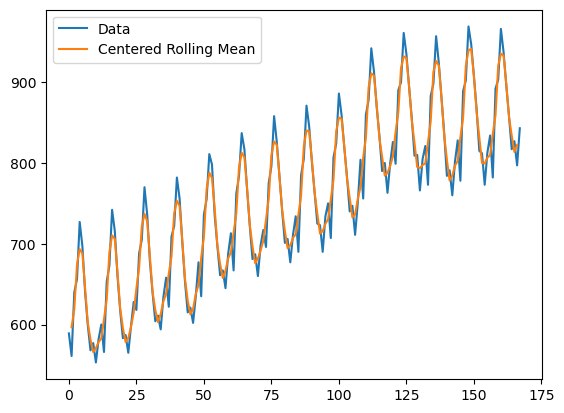

In [3]:
span = 3
df = pd.read_csv('monthly-milk-production-pounds-p.csv')
fcast = df['Milk'].rolling(span,center=True).mean()
plt.plot(df['Milk'], label = 'Data')
plt.plot(fcast, label='Centered Rolling Mean')
plt.legend(loc='best')
plt.show()

#### Train_test Split

In [4]:
y_train = df['Milk'][:-12]
y_test = df['Milk'][-12:] 

#### Trailing Rolling Mean

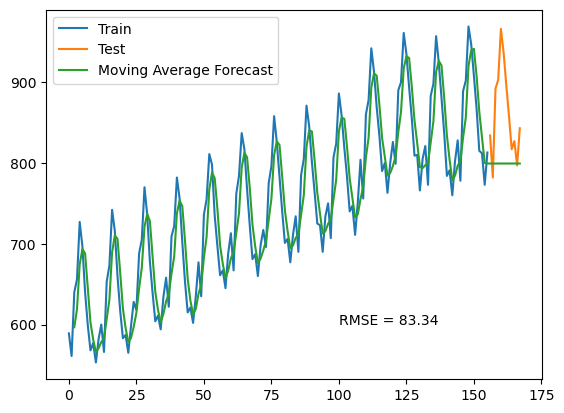

In [6]:
from sklearn.metrics import root_mean_squared_error


span = 3
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast, MA_series], ignore_index=True)
plt.plot(y_train, label='Train')
plt.plot(y_test, label='Test')
plt.plot(MA_fcast, label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test, MA_series),2)
plt.text(100,600, f"RMSE = {rms}")
plt.legend(loc='best')
plt.show()


#### Simple Exponential Mean

In [17]:
from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing

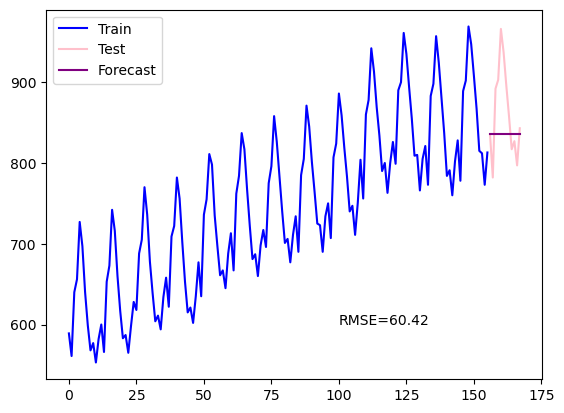

In [10]:
alpha = 0.2
ses_model = SimpleExpSmoothing(y_train).fit(smoothing_level=alpha,optimized=False)
fcast1 =ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100,600,f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

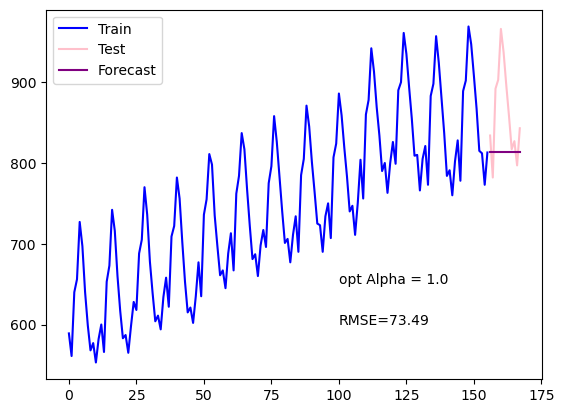

In [11]:
ses_model = SimpleExpSmoothing(y_train).fit(optimized=True)
fcast1 =ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
opt_alpha = np.round(ses_model.model.params['smoothing_level'], 2)
plt.text(100, 650, f"opt Alpha = {opt_alpha}")
plt.text(100,600,f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

#### Additive Damped Trend

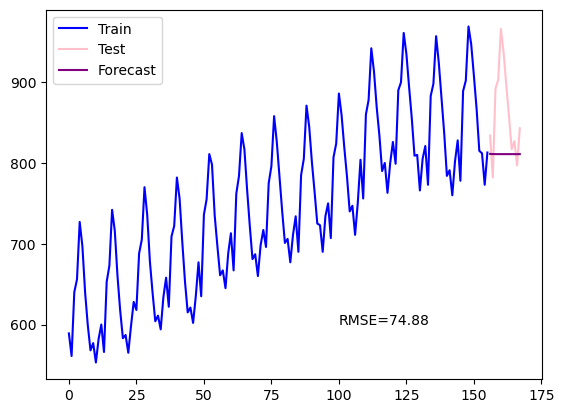

In [14]:
alpha, beta, phi = 0.4, 0.2, 0.3
holt = Holt(y_train, damped_trend = True)
fit1 = holt.fit(smoothing_level=alpha, smoothing_trend = beta, damping_trend = phi, optimized = False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100,600,f"RMSE={rms}")
plt.legend(loc='best')
plt.show()



d:\Anaconda\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


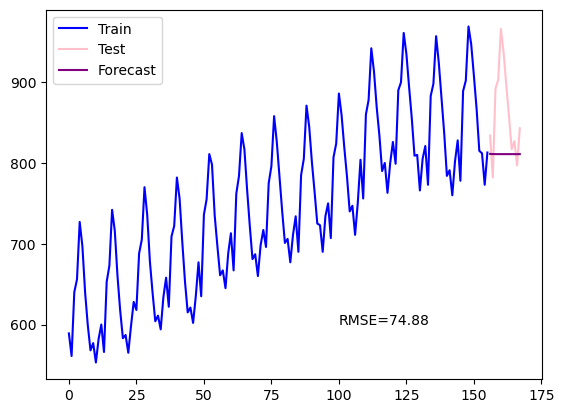

In [16]:
alpha, beta, phi = 0.4, 0.2, 0.3
holt = Holt(y_train, damped_trend = True)
fit1 = holt.fit(smoothing_level=alpha, smoothing_trend = beta, damping_trend = phi, optimized = True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100,600,f"RMSE={rms}")
plt.legend(loc='best')
plt.show()


#### Exponential Smoothing
* Holt Winter Additive

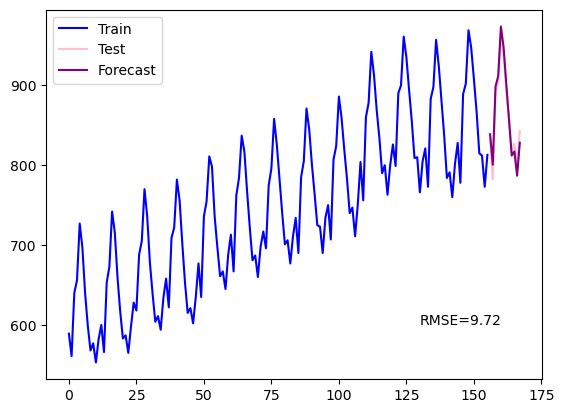

In [19]:
alpha, beta, gamma = 0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train, seasonal_periods=12, trend='add', seasonal='add')
fit1 = hw_add.fit(smoothing_level=alpha, smoothing_trend = beta, smoothing_seasonal= gamma)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(130,600,f"RMSE={rms}")
plt.legend(loc='best')
plt.show()


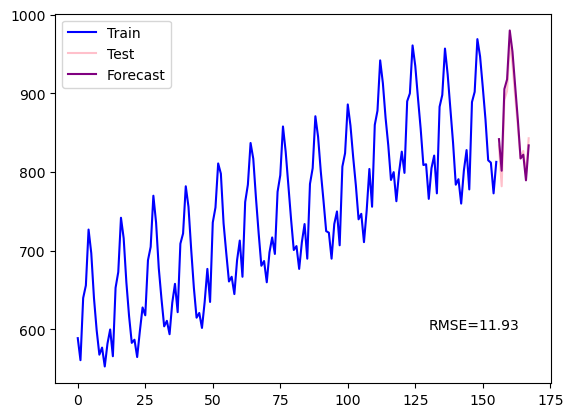

In [ ]:
# alpha, beta, gamma = 0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train, seasonal_periods=12, trend='add', seasonal='add')
fit1 = hw_add.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink", label='Test')
fcast1.plot(color="purple", label = "Forecast")
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(130,600,f"RMSE={rms}")
plt.text(120,580,)
plt.legend(loc='best')
plt.show()